# Лекция: Ad-hoc аналитика

### Разбор кейсов в коде для Школы Аналитиков

## 0. Подготовка окружения

Импортируем библиотеки, задаём пути и загружаем синтетические данные. SQL-запросы в ноутбуке исполняем локально через DuckDB, а пишем их близко к диалекту Trino. Отличия DuckDB, если они есть, отмечены в комментариях.

Запускайте ноутбук из каталога `analytics_school/` (рядом должна быть папка `data/`).


In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from IPython.display import display

try:
    import duckdb
except ImportError as e:
    raise ImportError("Нужен пакет duckdb для SQL-блоков: pip install duckdb") from e

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (10, 4)
plt.rcParams["axes.titlesize"] = 12

# Канонический путь: analytics_school/data рядом с ноутбуком
DATA = Path("data")
if not DATA.exists():
    # запасной вариант, если ядро запущено из корня репозитория
    DATA = Path("hh-science/k.guliev/analytics_school/data")

assert DATA.exists(), f"Не найдена папка с данными: {DATA.resolve()}"

# Регистрируем CSV как таблицы, чтобы обращаться к ним из SQL
con = duckdb.connect()

def register_csv(name: str, filename: str) -> pd.DataFrame:
    path = DATA / filename
    df = pd.read_csv(path)
    # year/month/day должны остаться строками с ведущими нулями ('07'),
    # иначе фильтр вида day BETWEEN '01' AND '28' сравнит строки неправильно
    for col in ("year", "month", "day"):
        if col in df.columns:
            if col == "year":
                df[col] = df[col].astype("Int64").astype(str)
            else:
                df[col] = df[col].astype("Int64").map(lambda x: f"{int(x):02d}" if pd.notna(x) else None)
    con.register(name, df)
    print(f"{name:28s} {len(df):>8,} строк  <- {filename}")
    return df

impressions = register_csv("impressions", "impressions.csv")
clicks = register_csv("clicks", "clicks.csv")
responses = register_csv("responses", "responses.csv")
product_daily = register_csv("product_daily", "product_daily.csv")
employer_spend = register_csv("employer_spend", "employer_spend.csv")
experiment_clients = register_csv("experiment_clients", "experiment_clients.csv")
incident_events = register_csv("incident_events", "incident_events.csv")

def sql(query: str) -> pd.DataFrame:
    # Выполнить SQL-запрос (в стиле Trino) к синтетическим таблицам
    return con.execute(query).df()

print("\nГотово. Для запросов используйте функцию sql('''...''').")


impressions                    80,000 строк  <- impressions.csv
clicks                          3,837 строк  <- clicks.csv
responses                         421 строк  <- responses.csv
product_daily                     252 строк  <- product_daily.csv
employer_spend                  2,400 строк  <- employer_spend.csv
experiment_clients             12,573 строк  <- experiment_clients.csv
incident_events                25,500 строк  <- incident_events.csv

Готово. Для запросов используйте функцию sql('''...''').


# Артефакт: готовые функции для ad-hoc

Ниже набор функций на сессию. Их можно копировать в свои ноутбуки. В кейсах они используются явно.

| Функция | Зачем |
|---|---|
| `wilson_ci` | Доверительный интервал для доли по методу Уилсона |
| `proportion_table` | Таблица долей с интервалами по группам |
| `period_flag` | Разметка строк на периоды «до» и «после» |
| `summarize_dq` | Быстрая сводка по качеству данных |
| `one_pager` | Шаблон итоговой справки |

**Про доверительный интервал (связь с курсом статистики).** Интервал Уилсона для доли при уровне 95% — диапазон неопределённости оценки на текущей выборке, а не доказательство причинности. Если интервалы двух платформ пересекаются, разницу нельзя уверенно объявлять «эффектом» без дополнительной проверки. Бутстрэп для прироста ниже — та же логика: устойчивость оценки, не замена эксперимента.


In [2]:
from typing import Iterable, Optional, Sequence, Tuple


def wilson_ci(successes: float, n: float, z: float = 1.96) -> Tuple[float, float]:
    # Доверительный интервал Уилсона для доли. Устойчивее нормального приближения
    # на малых выборках и у краёв (доля близка к 0 или 1).
    if n <= 0:
        return (np.nan, np.nan)
    p = successes / n
    denom = 1 + z**2 / n
    center = (p + z**2 / (2 * n)) / denom
    margin = z * np.sqrt((p * (1 - p) + z**2 / (4 * n)) / n) / denom
    return (max(0.0, center - margin), min(1.0, center + margin))


def proportion_table(
    df: pd.DataFrame,
    group_cols: Sequence[str],
    success_col: str,
    n_col: str,
    rate_name: str = "rate",
) -> pd.DataFrame:
    # Считает долю по группам и добавляет доверительный интервал Уилсона.
    g = df.groupby(list(group_cols), as_index=False).agg(
        successes=(success_col, "sum"),
        n=(n_col, "sum"),
    )
    g[rate_name] = g["successes"] / g["n"]
    cis = g.apply(lambda r: wilson_ci(r["successes"], r["n"]), axis=1)
    g["ci_low"] = cis.map(lambda x: x[0])
    g["ci_high"] = cis.map(lambda x: x[1])
    return g


def period_flag(dates: pd.Series, cutoff: str, before="before", after="after") -> pd.Series:
    # Размечает даты на период до и после точки cutoff.
    d = pd.to_datetime(dates)
    return np.where(d < pd.Timestamp(cutoff), before, after)


def summarize_dq(df: pd.DataFrame, key_cols: Optional[Iterable[str]] = None) -> pd.DataFrame:
    # Быстрая сводка по качеству данных: размер, дубли, пропуски по колонкам,
    # при указании ключа считаем также дубли по ключу.
    rows = []
    rows.append({"проверка": "строк всего", "значение": len(df)})
    rows.append({"проверка": "полных дублей строк", "значение": int(df.duplicated().sum())})
    for c in df.columns:
        rows.append({"проверка": f"пропуски: {c}", "значение": int(df[c].isna().sum())})
    if key_cols:
        key_cols = list(key_cols)
        rows.append({
            "проверка": f"дубли по ключу: {'+'.join(key_cols)}",
            "значение": int(df.duplicated(key_cols).sum()),
        })
    return pd.DataFrame(rows)


def one_pager(
    decision: str,
    context: str,
    what_done: str,
    result: str,
    limits: str,
    action: str,
) -> str:
    # Собирает итоговую справку с выводом наверху.
    parts = [
        "=" * 60,
        "ИТОГОВАЯ СПРАВКА",
        "=" * 60,
        "",
        "Решение:",
        decision,
        "",
        "Контекст:",
        context,
        "",
        "Что сделали:",
        what_done,
        "",
        "Результат:",
        result,
        "",
        "Ограничения:",
        limits,
        "",
        "Рекомендованное действие:",
        action,
        "=" * 60,
    ]
    return "\n".join(parts)


print("Функции загружены: wilson_ci, proportion_table, period_flag, summarize_dq, one_pager")


Функции загружены: wilson_ci, proportion_table, period_flag, summarize_dq, one_pager


Практические кейсы

Пять кейсов на разных ступенях глубины (раздел 1.4):

1. **Инцидент публикации** — «пожарный» вопрос и диалог уточнения ТЗ. Глубина: прикидка (так велит срок).
2. **Качество данных** — те же данные с дефектами и их влиянием на ответ. Показывает, чего не урезают даже в прикидке.
3. **Воронка** — подмена задачи «посчитай кликабельность». Глубина: разбор.
4. **Каннибализация** — основной сквозной кейс: новый формат в аукционе. Глубина: глубокий разбор.
5. **Разбор эксперимента** — решение о раскатке скидки (опционально по времени). Глубина: глубокий разбор.

| Датасет | Что внутри | В каком кейсе |
|---|---|---|
| `incident_events` | Попытки публикации вакансий со статусом ok/error | Кейсы 1–2 |
| `impressions`, `clicks`, `responses` | События воронки: показы, клики, отклики | Кейс 3 |
| `product_daily`, `employer_spend` | Дневной расход по продуктам и расход работодателей до/после запуска | Кейс 4 |
| `experiment_clients` | Клиенты эксперимента со скидками | Кейс 5 |


## Кейс 1. Инцидент: маленький ad-hoc закрывается парой запросов

### Контекст

Часть ad-hoc-задач приходит как «пожар»: заказчику нужен ответ в тот же день, чтобы принять операционное решение. Здесь важнее корректно сформулировать вопрос и быстро проверить масштаб, чем строить сложную модель.

В этом кейсе учимся:

- переводить короткий запрос из чата в ТЗ через диалог;
- отвечать двумя SQL-запросами и одним графиком;
- не усложнять метод, если решение уже однозначное.

### Диалог уточнения (как это выглядит в чате)

> **Тимлид поддержки:** 14 августа с 14:00 до 16:00 жаловались, что не публикуются вакансии. Это массово или единично?
>
> **Аналитик:** Какое решение примете по ответу?
>
> **Тимлид:** Если массово — поднимаем инцидент высокого приоритета. Если единично — разбираем точечно.
>
> **Аналитик:** Ок. Метрика — доля ошибок среди попыток публикации и число затронутых работодателей. Период 10–16 августа, внутри него окно 14:00–16:00. Разрез — платформа. Порог предлагаю согласовать так: около 0,01% — единичные случаи; порядка 10–15% и выше — инцидент. Порог ок?
>
> **Тимлид:** Да, давайте так. Нужно сегодня до конца дня.

Порог — договорённость с заказчиком, не универсальная норма.

| Поле ТЗ | Значение |
|---|---|
| Цель | Оценить масштаб сбоя публикации вакансий |
| Гипотеза | В окне 14:00–16:00 доля ошибок на порядок выше фона |
| Метрика | Доля ошибок среди попыток; число затронутых работодателей и вакансий |
| Период | 10–16 августа 2026; окно инцидента 14 августа с 14:00 до 16:00 |
| Сегменты | Платформа |
| Критерий | Около 0,01%: единичные случаи. Около 10–15% и выше: инцидент |
| Решение | Поднимать инцидент высокого приоритета или разбирать точечно |

Глубина: прикидка. По цене ошибки задача тянет на разбор, но ответ нужен сегодня, поэтому делаем прикидку и прямо говорим тимлиду, что ещё не проверили.

Поле `hour` в данных — час начала интервала (0…23). Условие `hour BETWEEN 14 AND 15` покрывает время с 14:00 до 15:59, то есть окно жалоб «14:00–16:00».


### Запрос 1: доля ошибок в окне инцидента против остального периода

Сравниваем окно 14 августа 14:00–16:00 с остальными днями периода. Если доля ошибок в окне на порядок выше фона, это массовый сбой, а не набор единичных жалоб.

Партиции фильтруем отдельными полями `year`, `month` и `day`, как в рабочем Querybook. `CONCAT(year, '-', month, '-', day)` читается удобнее, но хуже отсекает партиции.


In [3]:
# Наивная версия: качество данных пока не проверяли.
# hour — час начала: BETWEEN 14 AND 15 = [14:00, 16:00).

q_incident = '''
WITH base AS (
    SELECT
        event_date,
        hour,
        platform,
        employer_id,
        vacancy_id,
        status,
        CASE
            WHEN event_date = '2026-08-14' AND hour BETWEEN 14 AND 15
            THEN 1 ELSE 0
        END AS in_incident_window
    FROM incident_events
    WHERE year = '2026'
      AND month = '08'
      AND day BETWEEN '10' AND '16'
)
SELECT
    in_incident_window,
    COUNT(*) AS attempts,
    SUM(CASE WHEN status = 'error' THEN 1 ELSE 0 END) AS errors,
    100.0 * SUM(CASE WHEN status = 'error' THEN 1 ELSE 0 END) / COUNT(*) AS error_rate_pct,
    COUNT(DISTINCT CASE WHEN status = 'error' THEN employer_id END) AS employers_affected,
    COUNT(DISTINCT CASE WHEN status = 'error' THEN vacancy_id END) AS vacancies_affected
FROM base
GROUP BY 1
ORDER BY 1 DESC
'''

sql(q_incident)


,in_incident_window,attempts,errors,error_rate_pct,employers_affected,vacancies_affected
0,1,338,55.0,16.272189,52,53
1,0,25162,298.0,1.184326,285,293


### Запрос 2: разрез доли ошибок по платформам внутри окна инцидента

Нужен, чтобы понять, локализован ли сбой (например, только Android) или затронуты все платформы. От этого зависит, откатывать всё или чинить точечно.


In [4]:
q_by_platform = '''
SELECT
    platform,
    COUNT(*) AS attempts,
    SUM(CASE WHEN status = 'error' THEN 1 ELSE 0 END) AS errors,
    100.0 * SUM(CASE WHEN status = 'error' THEN 1 ELSE 0 END) / COUNT(*) AS error_rate_pct
FROM incident_events
WHERE event_date = '2026-08-14'
  AND hour BETWEEN 14 AND 15
GROUP BY 1
ORDER BY 4 DESC
'''

by_platform = sql(q_by_platform)
by_platform


,platform,attempts,errors,error_rate_pct
0,DESKTOP_WEB,139,25.0,17.985612
1,ANDROID,54,9.0,16.666667
2,IOS,57,9.0,15.789474
3,MOBILE_WEB,85,12.0,14.117647
4,None,3,0.0,0.000000


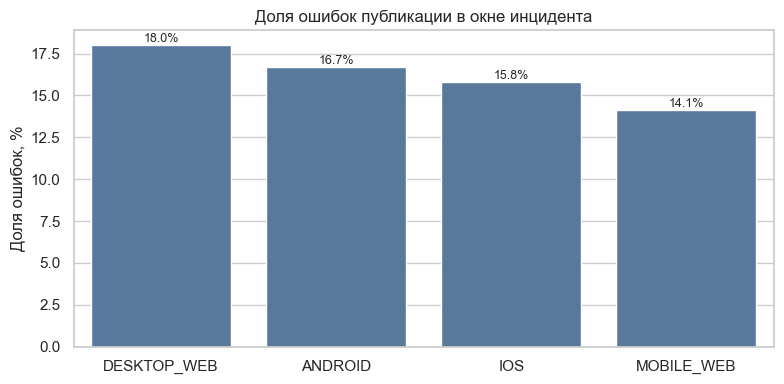

ИТОГОВАЯ СПРАВКА

Решение:
Черновик: поднимать инцидент высокого приоритета — в окне доля ошибок около 16%, затронуты сотни работодателей.

Контекст:
Жалобы на публикацию вакансий 14 августа с 14 до 16 часов.

Что сделали:
Сравнили долю ошибок в окне и в остальном периоде, добавили разрез по платформам.

Результат:
В окне доля ошибок на порядок выше фонового уровня (около 1%). Эффект виден на всех платформах.

Ограничения:
Качество данных ещё не проверяли — цифру пересмотрим в кейсе 2. Логов бэкенда нет, корневую причину не диагностировали.

Рекомендованное действие:
Пока открыть инцидент; после проверки качества данных подтвердить или скорректировать оценку доли ошибок.


In [5]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(data=by_platform, x="platform", y="error_rate_pct", ax=ax, color="#4C78A8")
ax.set_title("Доля ошибок публикации в окне инцидента")
ax.set_ylabel("Доля ошибок, %")
ax.set_xlabel("")
for p in ax.patches:
    ax.annotate(f"{p.get_height():.1f}%", (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom", fontsize=9)
plt.tight_layout()
plt.show()

print(
    one_pager(
        decision="Черновик: поднимать инцидент высокого приоритета — в окне доля ошибок около 16%, затронуты сотни работодателей.",
        context="Жалобы на публикацию вакансий 14 августа с 14 до 16 часов.",
        what_done="Сравнили долю ошибок в окне и в остальном периоде, добавили разрез по платформам.",
        result="В окне доля ошибок на порядок выше фонового уровня (около 1%). Эффект виден на всех платформах.",
        limits="Качество данных ещё не проверяли — цифру пересмотрим в кейсе 2. Логов бэкенда нет, корневую причину не диагностировали.",
        action="Пока открыть инцидент; после проверки качества данных подтвердить или скорректировать оценку доли ошибок.",
    )
)


### После кейса 1

Задача «пожарная», поэтому мы не строили модель и не уходили в корневую причину. Двумя запросами сравнили долю ошибок в окне с фоном и проверили, что эффект есть на всех платформах. Этого достаточно для черновика ответа «да, это массово».

Оговорка: запрос наивный. Дубли, пропуски и разнобой в статусах ещё не проверяли. Итоговая справка выше помечена как **черновик** — цифру пересмотрим в кейсе 2.

| Что отработали | Пункт |
|---|---|
| Свойство ad-hoc | Ограниченное время, направленность на решение |
| Глубина | Прикидка: ответ нужен сегодня, ограничения названы заказчику |
| Семь вопросов до SQL | Цель, метрика, период, сегменты, критерий, решение; диалог уточнения |
| Урок | Справка до проверки качества данных — только черновик |


## Кейс 2. Проверка качества данных (тот же инцидент)

### Контекст

Прежде чем называть заказчику число, проверяем данные. Пропуски, дубли, разнобой в написании категорий и невалидные значения часто объясняют, почему два аналитика на одном вопросе получают разные цифры. Проверка качества данных в ad-hoc обязательна, а не «когда будет время».

В синтетику намеренно заложены типовые дефекты:

1. Полные дубли строк и дубли по ключу события (`event_id`).
2. Разнобой регистра в поле `status`: `error`, `Error`, `ERROR`.
3. Пропуски в `platform` и `employer_id`.
4. Невалидные значения `hour` (встречается 24).

Цель кейса: понять, ломают ли эти дефекты вывод «это инцидент», и какую оценку доли ошибок можно отдавать заказчику.

| Поле ТЗ | Значение |
|---|---|
| Цель | Проверить, не искажают ли дефекты данных оценку доли ошибок |
| Метрика | Число дублей, пропусков, некорректных значений; доля ошибок до и после очистки |
| Период | 10–16 августа 2026 |
| Решение | Использовать наивную оценку или пересчитать на очищенных данных |

Порядок проверки:

1. Размер таблицы и полные дубли строк.
2. Дубли по ключу события.
3. Пропуски по колонкам.
4. Разнобой в категориальных полях.
5. Диапазоны числовых полей.


In [6]:
# Быстрая сводка по качеству данных: размер, дубли, пропуски, дубли по ключу
display(summarize_dq(incident_events, key_cols=["event_id"]))


,проверка,значение
0,строк всего,25500
1,полных дублей строк,500
2,пропуски: event_id,0
3,пропуски: event_ts,0
4,пропуски: event_date,0
5,пропуски: hour,0
6,пропуски: platform,253
7,пропуски: employer_id,155
8,пропуски: vacancy_id,0
9,пропуски: status,0


### Дефект 1: разнобой в значениях статуса

Наивный запрос из кейса 1 фильтровал строго `status = 'error'`. Если в логах есть `ERROR` или `Error`, часть ошибок не попадёт в числитель, и доля ошибок будет занижена.


In [7]:
# Наивный запрос из кейса 1 фильтровал строго status = 'error'.
# Проверим, какие варианты статуса вообще встречаются в данных.
status_variants = sql('''
SELECT DISTINCT status FROM incident_events
''')
display(status_variants)

# Сколько строк-ошибок теряет наивный фильтр из-за регистра
lost = sql('''
SELECT
    SUM(CASE WHEN status = 'error' THEN 1 ELSE 0 END) AS naive_errors,
    SUM(CASE WHEN LOWER(status) = 'error' THEN 1 ELSE 0 END) AS all_errors
FROM incident_events
''')
display(lost)
print("Наивный фильтр теряет ошибок:", int(lost['all_errors'][0] - lost['naive_errors'][0]))


,status
0,ERROR
1,error
2,ok
3,Error


,naive_errors,all_errors
0,353.0,383.0


Наивный фильтр теряет ошибок: 30


### Дефект 2: невалидный час и пропуски в платформе

`hour` должен быть от 0 до 23. Значение 24 обычно означает сбой парсинга времени: такие строки могут выпадать из окна инцидента или попадать в него ошибочно. Пропуски в `platform` ломают разрезы: часть ошибок «пропадёт» из разбивки по платформам.


In [9]:
# Диапазон hour: значения должны быть 0..23. Значение 24 обычно означает сбой парсинга времени.
hour_range = sql('''
SELECT MIN(hour) AS min_hour, MAX(hour) AS max_hour FROM incident_events
''')
display(hour_range)

# Пропуски в ключевых полях
nulls = sql('''
SELECT
    COUNTIF(event_id IS NULL) AS nulls_event_id, 
    COUNTIF(platform IS NULL) AS nulls_platform, 
    COUNTIF(employer_id IS NULL) AS nulls_employer_id, 
FROM incident_events
''')
display(nulls)


,min_hour,max_hour
0,0,24


,nulls_event_id,nulls_platform,nulls_employer_id
0,0.0,253.0,155.0


### Как дефекты влияют на ответ из кейса 1

Сравним долю ошибок в окне: наивную оценку и оценку после очистки. Очистка: **дедупликация по `event_id`** (не путать с `SELECT DISTINCT *` — при частичных дублях это разные операции) и приведение статуса к нижнему регистру. Важно не только «насколько цифра сдвинулась», но и «изменился ли вывод для заказчика».


,method,attempts,error_rate_pct
0,наивная оценка,338,16.272189
1,после очистки,333,17.417417


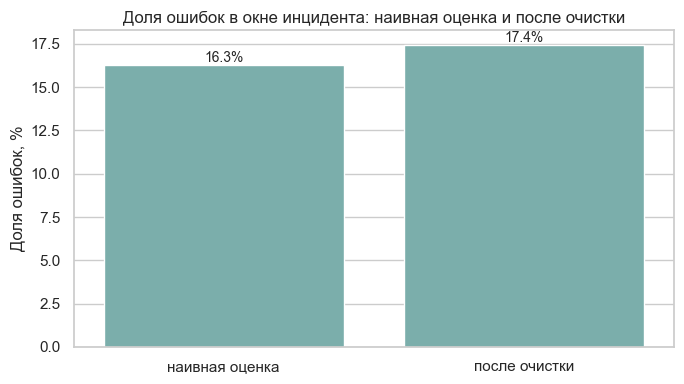

ИТОГОВАЯ СПРАВКА

Решение:
Вывод кейса 1 подтверждается: это инцидент. Для ответа заказчику берём очищенную долю ошибок, а не наивную.

Контекст:
Проверка качества таблицы попыток публикации перед тем, как доверять доле ошибок.

Что сделали:
Нашли дубли по ключу события, пропуски, разнобой регистра в статусе, невалидный час=24. Пересчитали долю ошибок после дедупа по event_id и LOWER(status).

Результат:
Дубли завышают число попыток, разнобой регистра занижает число ошибок. После очистки доля ошибок в окне около 17% против наивных 16%. Вывод «это инцидент» не меняется.

Ограничения:
Корневую причину дефектов (двойное логирование, парсинг времени) в этой задаче не устраняли.

Рекомендованное действие:
В расчётах по этой таблице дедуплицировать по ключу события и приводить статус к нижнему регистру. Завести проверку на диапазон часа.


In [10]:
# Сравниваем наивную оценку и очистку: дедуп по event_id + LOWER(status).
# Не используем DISTINCT *: при частичных дублях это другая операция.
comparison = sql('''
WITH win AS (
    SELECT * FROM incident_events
    WHERE event_date = '2026-08-14' AND hour BETWEEN 14 AND 15
),
naive AS (
    SELECT
        'наивная оценка' AS method,
        COUNT(*) AS attempts,
        100.0 * SUM(CASE WHEN status = 'error' THEN 1 ELSE 0 END) / COUNT(*) AS error_rate_pct
    FROM win
),
dedup AS (
    SELECT *
    FROM (
        SELECT
            *,
            ROW_NUMBER() OVER (PARTITION BY event_id ORDER BY event_date, hour) AS rn
        FROM win
    ) t
    WHERE rn = 1
),
cleaned AS (
    SELECT
        'после очистки' AS method,
        COUNT(*) AS attempts,
        100.0 * SUM(CASE WHEN LOWER(status) = 'error' THEN 1 ELSE 0 END) / COUNT(*) AS error_rate_pct
    FROM dedup
)
SELECT * FROM naive
UNION ALL
SELECT * FROM cleaned
'''
)
display(comparison)

fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(data=comparison, x="method", y="error_rate_pct", ax=ax, color="#72B7B2")
ax.set_title("Доля ошибок в окне инцидента: наивная оценка и после очистки")
ax.set_ylabel("Доля ошибок, %")
ax.set_xlabel("")
for p in ax.patches:
    ax.annotate(f"{p.get_height():.1f}%", (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom", fontsize=10)
plt.tight_layout()
plt.show()

print(
    one_pager(
        decision="Вывод кейса 1 подтверждается: это инцидент. Для ответа заказчику берём очищенную долю ошибок, а не наивную.",
        context="Проверка качества таблицы попыток публикации перед тем, как доверять доле ошибок.",
        what_done="Нашли дубли по ключу события, пропуски, разнобой регистра в статусе, невалидный час=24. Пересчитали долю ошибок после дедупа по event_id и LOWER(status).",
        result="Дубли завышают число попыток, разнобой регистра занижает число ошибок. После очистки доля ошибок в окне около 17% против наивных 16%. Вывод «это инцидент» не меняется.",
        limits="Корневую причину дефектов (двойное логирование, парсинг времени) в этой задаче не устраняли.",
        action="В расчётах по этой таблице дедуплицировать по ключу события и приводить статус к нижнему регистру. Завести проверку на диапазон часа.",
    )
)


### После кейса 2

Дубли по ключу события завышают число попыток. Разнобой в регистре статуса прячет часть ошибок от наивного фильтра. Невалидный час и пропуски искажают агрегаты и разрезы. Вывод «это инцидент» устоял, но точность цифры зависит от очистки — поэтому проверку качества делаем до финального числа для заказчика.


## Кейс 3. Воронка «показ → клик → отклик» по платформам

### Контекст

Классическая ловушка продуктовой и рекламной аналитики: оптимизировать промежуточную метрику в отрыве от бизнес-цели. Рекламный блок или сниппет может собирать много кликов и при этом не приводить к целевому действию. В нашем случае целевое действие: отклик на вакансию. Поэтому смотрим не одну метрику, а всю воронку.

| Как говорим | Формула | В коде |
|---|---|---|
| Кликабельность | клики / показы | `ctr_pct` |
| Конверсия из клика в отклик | отклики / клики | `cvr_pct` |
| Конверсия из показа в отклик | отклики / показы | `response_rate_pct` |

### Запрос от продакта рекламного блока

> «Посчитай кликабельность баннера в выдаче.»

Здесь видна подмена задачи: просят кликабельность, а боль в том, что «блок не приносит откликов». Высокая кликабельность при низкой конверсии из клика в отклик означает кликбейт.

| Поле ТЗ | Значение |
|---|---|
| Цель | Понять, где «ломается» воронка: на клике или на отклике |
| Гипотеза | На вебе высокая кликабельность, но низкая конверсия из клика в отклик |
| Метрика | Кликабельность; конверсия из клика в отклик; конверсия из показа в отклик |
| Период | 1–28 июля 2026 |
| Сегменты | Платформа и продукт |
| Критерий | Ищем платформу, где кликабельность выше, а конверсия из клика в отклик ниже медианы |
| Решение | Куда направить силы: в кликабельность или в релевантность блока |
| Глубина | Разбор: цена ошибки средняя (решение про формат блока), блок можно откатить без следа |

Данные: три таблицы, связанные по ключам: показы (`impressions`), клики (`clicks`), отклики (`responses`).


In [11]:
# Сначала - проверка качества данных перед расчётом метрик
display(summarize_dq(impressions, key_cols=["impression_id"]))
display(summarize_dq(clicks, key_cols=["click_id"]))
orphan_clicks = (~clicks["impression_id"].isin(impressions["impression_id"])).sum()
print("Клики без соответствующего показа (осиротевшие):", int(orphan_clicks))


,проверка,значение
0,строк всего,80000
1,полных дублей строк,0
2,пропуски: impression_id,0
3,пропуски: event_date,0
4,пропуски: platform,0
5,пропуски: segment,0
6,пропуски: product,0
7,пропуски: vacancy_id,0
8,пропуски: employer_id,0
9,пропуски: hhuid,0


,проверка,значение
0,строк всего,3837
1,полных дублей строк,0
2,пропуски: click_id,0
3,пропуски: impression_id,0
4,пропуски: event_date,0
5,пропуски: platform,0
6,пропуски: segment,0
7,пропуски: product,0
8,пропуски: vacancy_id,0
9,пропуски: employer_id,0


Клики без соответствующего показа (осиротевшие): 0


### Запрос: воронка по платформам и продуктам

Собираем показы, клики и отклики в одну таблицу. Считаем кликабельность, конверсию из клика в отклик и конверсию из показа в отклик. Смотрим разрезы по платформе и продукту: средний итог по всем платформам легко прячет кликбейт на вебе.


In [12]:
q_funnel = '''
WITH impr AS (
    SELECT platform, product, COUNT(*) AS impressions
    FROM impressions
    WHERE year = '2026' AND month = '07' AND day BETWEEN '01' AND '28'
    GROUP BY 1, 2
),
clk AS (
    SELECT platform, product, COUNT(*) AS clicks
    FROM clicks
    WHERE year = '2026' AND month = '07' AND day BETWEEN '01' AND '28'
    GROUP BY 1, 2
),
rsp AS (
    SELECT platform, product, COUNT(*) AS responses
    FROM responses
    WHERE year = '2026' AND month = '07' AND day BETWEEN '01' AND '28'
    GROUP BY 1, 2
)
SELECT
    i.platform,
    i.product,
    i.impressions,
    COALESCE(c.clicks, 0) AS clicks,
    COALESCE(r.responses, 0) AS responses,
    100.0 * COALESCE(c.clicks, 0) / i.impressions AS ctr_pct,
    100.0 * COALESCE(r.responses, 0) / NULLIF(COALESCE(c.clicks, 0), 0) AS cvr_pct,
    100.0 * COALESCE(r.responses, 0) / i.impressions AS response_rate_pct
FROM impr i
LEFT JOIN clk c ON c.platform = i.platform AND c.product = i.product
LEFT JOIN rsp r ON r.platform = i.platform AND r.product = i.product
ORDER BY i.platform, i.product
'''

funnel = sql(q_funnel)
funnel


,platform,product,impressions,clicks,responses,ctr_pct,cvr_pct,response_rate_pct
0,ANDROID,top_boost,3325,165,32,4.962406,19.393939,0.962406
1,ANDROID,top_search,14281,480,67,3.361109,13.958333,0.469155
2,DESKTOP_WEB,top_boost,5854,424,21,7.242911,4.952830,0.358729
3,DESKTOP_WEB,top_search,24328,1343,118,5.520388,8.786299,0.485038
4,IOS,top_boost,2765,117,27,4.231465,23.076923,0.976492
5,IOS,top_search,11856,377,68,3.179825,18.037135,0.573549
6,MOBILE_WEB,top_boost,3355,219,21,6.527571,9.589041,0.625931
7,MOBILE_WEB,top_search,14236,712,67,5.001405,9.410112,0.470638


In [13]:
# Кликабельность с интервалом Уилсона через proportion_table.
# Долю без интервала на выборках разного размера сравнивать некорректно.
funnel_ci = proportion_table(
    funnel.rename(columns={"clicks": "successes", "impressions": "n"}),
    group_cols=["platform", "product"],
    success_col="successes",
    n_col="n",
    rate_name="ctr",
)
funnel_ci = funnel_ci.merge(
    funnel[["platform", "product", "clicks", "impressions"]],
    on=["platform", "product"],
    how="left",
)

plot_df = funnel_ci[funnel_ci["product"] == "top_search"].copy()

fig = go.Figure()
fig.add_trace(go.Bar(
    name="Кликабельность",
    x=plot_df["platform"],
    y=plot_df["ctr"],
    error_y=dict(
        type="data",
        array=plot_df["ci_high"] - plot_df["ctr"],
        arrayminus=plot_df["ctr"] - plot_df["ci_low"],
    ),
))
fig.update_layout(
    title="Кликабельность по платформам (продукт top_search), интервал Уилсона 95%",
    yaxis_tickformat=".1%",
    yaxis_title="Кликабельность",
    height=380,
)
fig.show()


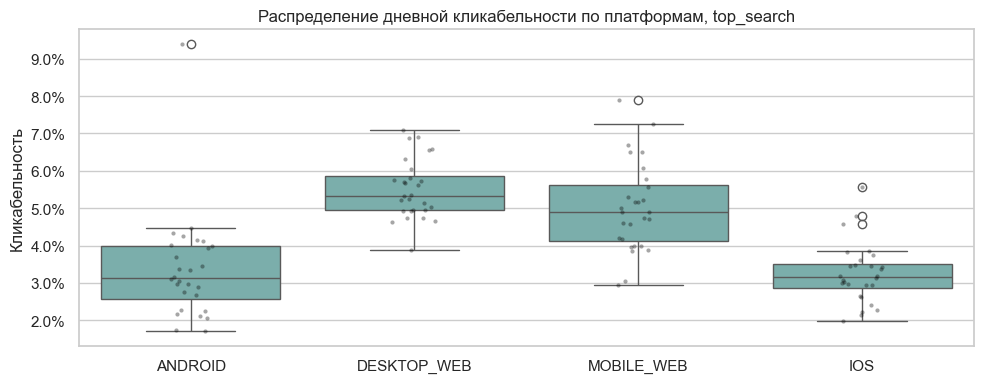

Дни Android с самой высокой кликабельностью (кандидаты на проблему трекинга):


,event_date,platform,impressions,clicks,ctr
46,2026-07-20,ANDROID,383,36.0,0.093995
91,2026-07-27,ANDROID,380,17.0,0.044737
33,2026-07-09,ANDROID,598,26.0,0.043478


In [14]:
# Показываем не только средние, но и распределение: дневная кликабельность по платформам.
daily = sql('''
SELECT
    i.event_date,
    i.platform,
    COUNT(*) AS impressions,
    SUM(CASE WHEN c.click_id IS NOT NULL THEN 1 ELSE 0 END) AS clicks
FROM impressions i
LEFT JOIN clicks c ON c.impression_id = i.impression_id
WHERE i.product = 'top_search'
  AND i.year = '2026' AND i.month = '07' AND i.day BETWEEN '01' AND '28'
GROUP BY 1, 2
''')
daily["ctr"] = daily["clicks"] / daily["impressions"]

fig, ax = plt.subplots(figsize=(10, 4))
sns.boxplot(data=daily, x="platform", y="ctr", ax=ax, color="#72B7B2")
sns.stripplot(data=daily, x="platform", y="ctr", ax=ax, color="black", size=3, alpha=0.35)
ax.set_title("Распределение дневной кликабельности по платформам, top_search")
ax.set_ylabel("Кликабельность")
ax.set_xlabel("")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.1%}"))
plt.tight_layout()
plt.show()

# Ищем выброс трекинга: аномально высокая кликабельность на Android
anomaly = daily[(daily["platform"] == "ANDROID")].sort_values("ctr", ascending=False).head(3)
print("Дни Android с самой высокой кликабельностью (кандидаты на проблему трекинга):")
display(anomaly)


In [15]:
# Диагностика кликбейта: сопоставляем кликабельность и конверсию из клика в отклик.
agg = funnel.groupby("platform", as_index=False).agg(
    impressions=("impressions", "sum"),
    clicks=("clicks", "sum"),
    responses=("responses", "sum"),
)
agg["ctr"] = agg["clicks"] / agg["impressions"]
agg["cvr"] = agg["responses"] / agg["clicks"]

fig = px.scatter(
    agg, x="ctr", y="cvr", text="platform", size="impressions",
    title="Кликабельность и конверсия из клика в отклик по платформам (размер точки показывает число показов)",
    labels={"ctr": "Кликабельность", "cvr": "Конверсия из клика в отклик"},
)
fig.update_traces(textposition="top center")
fig.update_layout(xaxis_tickformat=".1%", yaxis_tickformat=".1%", height=420)
fig.show()

print(
    one_pager(
        decision="Не оптимизировать кликабельность в отрыве от воронки. На десктоп-вебе кликабельность высокая, а конверсия из клика в отклик низкая. Усилия нужны на релевантность сниппета и посадочной, а не на «ещё больше кликов».",
        context="Запрос «посчитай кликабельность» переформулировали в анализ всей воронки: показ, клик, отклик.",
        what_done="Построили воронку по платформам и продуктам, добавили интервал Уилсона для кликабельности через proportion_table, посмотрели распределение дневной кликабельности и нашли выброс трекинга.",
        result="На вебе кликабельность высокая, а конверсия из клика в отклик низкая. В приложениях наоборот. На Android 20 июля виден выброс: вероятно, двойное логирование кликов.",
        limits="Окно атрибуции отклика не учтено. Смена состава продуктов после 15 июля влияет на агрегаты.",
        action="1) Проверить трекинг Android за 20 июля. 2) В дизайн-тестах целиться в конверсию из показа в отклик, а не в кликабельность. 3) Продукты top_search и top_boost смотреть раздельно.",
    )
)


ИТОГОВАЯ СПРАВКА

Решение:
Не оптимизировать кликабельность в отрыве от воронки. На десктоп-вебе кликабельность высокая, а конверсия из клика в отклик низкая. Усилия нужны на релевантность сниппета и посадочной, а не на «ещё больше кликов».

Контекст:
Запрос «посчитай кликабельность» переформулировали в анализ всей воронки: показ, клик, отклик.

Что сделали:
Построили воронку по платформам и продуктам, добавили интервал Уилсона для кликабельности через proportion_table, посмотрели распределение дневной кликабельности и нашли выброс трекинга.

Результат:
На вебе кликабельность высокая, а конверсия из клика в отклик низкая. В приложениях наоборот. На Android 20 июля виден выброс: вероятно, двойное логирование кликов.

Ограничения:
Окно атрибуции отклика не учтено. Смена состава продуктов после 15 июля влияет на агрегаты.

Рекомендованное действие:
1) Проверить трекинг Android за 20 июля. 2) В дизайн-тестах целиться в конверсию из показа в отклик, а не в кликабельность. 3) Продукты top_se

### После кейса 3

Вместо одной метрики построили всю воронку. Высокая кликабельность на вебе не превращается в отклики — оптимизировать её в отрыве от цели бессмысленно. Интервал нужен, потому что выборки разного размера. Распределение дневной кликабельности помогло заметить выброс на Android. Вывод для заказчика — это действие (куда направить силы), а не набор чисел.


## Кейс 4 (основной). Каннибализация нового формата в аукционе

### Контекст

Когда рядом с существующим продуктом запускают новый, возникает вопрос, приносит ли формат дополнительные деньги (инкремент) или перетягивает бюджет с уже существующего продукта (каннибализация)? Ответ определяет, стоит ли раскатывать формат и на каких сегментах.

15 июля 2026 рядом с классическим продуктом `top_search` запустили новый рекламный формат `top_boost`.

Продакт пишет:

> «Общий чистый расход вроде вырос, но по top_search он просел. Это каннибализация или инкремент? Решаем: оставлять новый формат всем, только крупным клиентам или выключать.»

Метрики и понятия кейса:

| Как говорим | Что это |
|---|---|
| Чистый расход | Списания рекламодателя без НДС и бонусов |
| Каннибализация | Расход и отклики, которые были бы в `top_search`, но ушли в `top_boost` |
| Инкремент | Дополнительный расход и отклики, которых без нового формата не было бы |
| Прирост | Разница между группой с доступом к формату и контролем |

В коде: `net_spend`, `cannibalization_est`, `incremental_est`.


### Шаг 1. Заполняем ТЗ до первой строки SQL

| Поле | Формулировка |
|---|---|
| Проблема | Неясно, новый формат приносит деньги или перетягивает бюджет с top_search |
| Цель | Оценить инкремент чистого расхода и откликов против каннибализации по сегментам |
| Гипотеза | У малого бизнеса новый формат в основном каннибализирует; у крупных клиентов больше инкремента |
| Метрика | Чистый расход и отклики; изменение суммарного расхода и расхода top_search; какая часть расхода нового формата инкрементальна |
| Период | До запуска: 17.06–14.07; после: 15.07–11.08 (по 4 недели) |
| Сегменты | Малый бизнес (SMB), крупные (Large), премиум (Premium); с доступом к формату и без него |
| Критерий успеха | Порог от заказчика (юнит-экономика продукта): суммарный расход +≥10%, просадка top_search не глубже −15% |
| Решение | Раскатать всем, раскатать только крупным, выключить или поменять прайс |
| Глубина | Глубокий разбор: на кону деньги клиентов, бюджеты уже перетекли, без следа не откатить. Проверка качества данных, разрезы, два способа оценки (шаги 3 и 4), интервал по бутстрэпу |

Дизайн без полноценного A/B: сравниваем работодателей с доступом к формату и без него, а также динамику дневного расхода до и после запуска. Это наблюдательная оценка: смещение отбора полностью не убираем, поэтому в конце явно фиксируем ограничения.


In [16]:
LAUNCH = "2026-07-15"

# Проверка качества данных
display(summarize_dq(product_daily))
display(summarize_dq(employer_spend, key_cols=["employer_id"]))

product_daily["event_date"] = pd.to_datetime(product_daily["event_date"])
product_daily["period"] = period_flag(product_daily["event_date"], LAUNCH)

print("Строк в product_daily:", len(product_daily))
print(product_daily.groupby(["period", "product"]).size())


,проверка,значение
0,строк всего,252
1,полных дублей строк,0
2,пропуски: event_date,0
3,пропуски: product,0
4,пропуски: segment,0
5,пропуски: net_spend,0
6,пропуски: impressions,0
7,пропуски: clicks,0
8,пропуски: responses,0
9,пропуски: year,0


,проверка,значение
0,строк всего,2400
1,полных дублей строк,0
2,пропуски: employer_id,0
3,пропуски: segment,0
4,пропуски: exposed_to_boost,0
5,пропуски: pre_period_start,0
6,пропуски: pre_period_end,0
7,пропуски: post_period_start,0
8,пропуски: post_period_end,0
9,пропуски: pre_net_spend_top_search,0


Строк в product_daily: 252
period  product   
after   top_boost     84
        top_search    84
before  top_search    84
dtype: int64


### Шаг 2. Динамика чистого расхода до и после запуска

Сначала смотрим картину целиком: что произошло с расходом `top_search` и `top_boost` после 15 июля, и вырос ли суммарный расход. Без этого легко принять рост нового продукта за успех, не заметив просадку старого.


/var/folders/yv/65mb5j6j7w16s0h33fqfpk3w0000gp/T/ipykernel_62405/2358465855.py:12: UserWarning: Glyph 8381 (\N{RUBLE SIGN}) missing from font(s) Arial.
  plt.tight_layout()
/Users/k.guliev/Library/Python/3.9/lib/python/site-packages/IPython/core/pylabtools.py:152: UserWarning: Glyph 8381 (\N{RUBLE SIGN}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


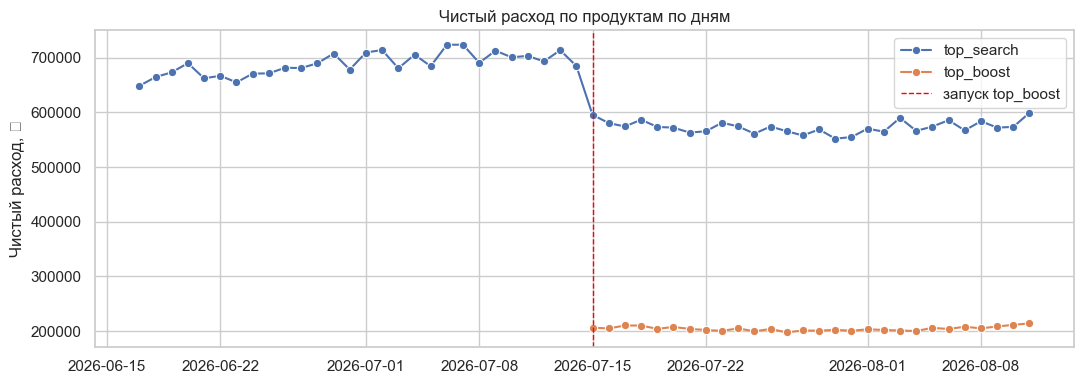

/var/folders/yv/65mb5j6j7w16s0h33fqfpk3w0000gp/T/ipykernel_62405/2358465855.py:33: UserWarning: Glyph 8381 (\N{RUBLE SIGN}) missing from font(s) Arial.
  plt.tight_layout()
/Users/k.guliev/Library/Python/3.9/lib/python/site-packages/IPython/core/pylabtools.py:152: UserWarning: Glyph 8381 (\N{RUBLE SIGN}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


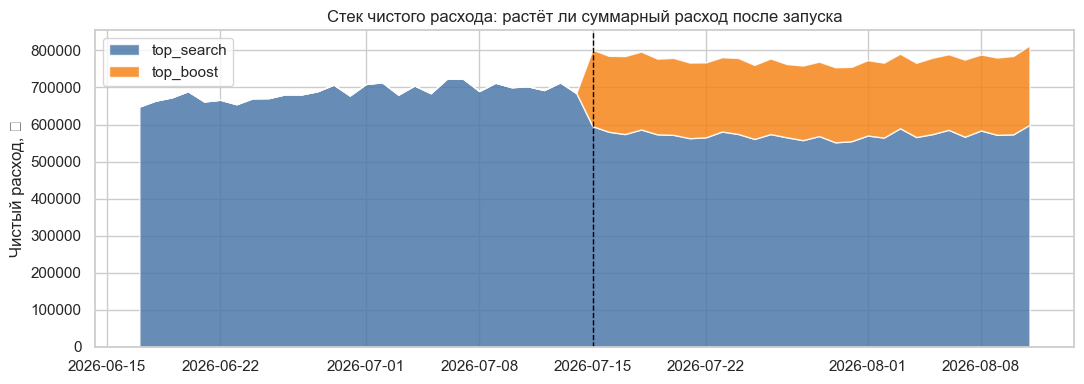

In [17]:
daily_total = (
    product_daily.groupby(["event_date", "product"], as_index=False)["net_spend"].sum()
)

fig, ax = plt.subplots(figsize=(11, 4))
sns.lineplot(data=daily_total, x="event_date", y="net_spend", hue="product", marker="o", ax=ax)
ax.axvline(pd.Timestamp(LAUNCH), color="red", ls="--", lw=1, label="запуск top_boost")
ax.set_title("Чистый расход по продуктам по дням")
ax.set_ylabel("Чистый расход, ₽")
ax.set_xlabel("")
ax.legend()
plt.tight_layout()
plt.show()

# Складываем расход в стек, чтобы увидеть, растёт ли суммарный расход
pivot = daily_total.pivot(index="event_date", columns="product", values="net_spend").fillna(0)
pivot["total"] = pivot.sum(axis=1)

fig, ax = plt.subplots(figsize=(11, 4))
ax.stackplot(
    pivot.index,
    pivot.get("top_search", 0),
    pivot.get("top_boost", 0),
    labels=["top_search", "top_boost"],
    colors=["#4C78A8", "#F58518"],
    alpha=0.85,
)
ax.axvline(pd.Timestamp(LAUNCH), color="black", ls="--", lw=1)
ax.set_title("Стек чистого расхода: растёт ли суммарный расход после запуска")
ax.set_ylabel("Чистый расход, ₽")
ax.set_xlabel("")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()


### Шаг 3. Агрегаты до/после и верхняя оценка каннибализации

Считаем **грубую верхнюю оценку** (при прочих равных):

- каннибализация ≈ насколько просел `top_search` после запуска (если просел);
- инкремент ≈ расход `top_boost` минус эта каннибализация.

Всё падение `top_search` здесь приписывается новому формату. Без контроля это легко перепутать с сезонностью или сдвигом трафика. Шаг 3 только **поднимает подозрение** по сегментам; шаг 4 проверяет его сравнением «с доступом / без доступа».


In [18]:
# Агрегируем расход и отклики по периоду, сегменту и продукту
seg = (
    product_daily.groupby(["period", "segment", "product"], as_index=False)
    .agg(net_spend=("net_spend", "sum"), responses=("responses", "sum"))
)

pre = seg[seg["period"] == "before"].rename(columns={"net_spend": "pre_spend", "responses": "pre_resp"})
post = seg[seg["period"] == "after"].rename(columns={"net_spend": "post_spend", "responses": "post_resp"})

# Базовый уровень top_search до запуска
pre_ts = pre[pre["product"] == "top_search"][["segment", "pre_spend", "pre_resp"]]
post_ts = post[post["product"] == "top_search"][["segment", "post_spend", "post_resp"]]
post_tb = post[post["product"] == "top_boost"][["segment", "post_spend", "post_resp"]].rename(
    columns={"post_spend": "boost_spend", "post_resp": "boost_resp"}
)

cann = (
    pre_ts.merge(post_ts, on="segment")
    .merge(post_tb, on="segment", how="left")
    .fillna(0)
)
cann["delta_top_search"] = cann["post_spend"] - cann["pre_spend"]
cann["post_total"] = cann["post_spend"] + cann["boost_spend"]
cann["delta_total"] = cann["post_total"] - cann["pre_spend"]
# Верхняя оценка каннибализации: насколько просел top_search (если изменение отрицательное)
cann["cannibalization_est"] = np.minimum(0, cann["delta_top_search"]).abs()
cann["incremental_est"] = cann["boost_spend"] - cann["cannibalization_est"]
cann["delta_total_pct"] = cann["delta_total"] / cann["pre_spend"]
cann["delta_ts_pct"] = cann["delta_top_search"] / cann["pre_spend"]

cann_view = cann[[
    "segment", "pre_spend", "post_spend", "boost_spend", "post_total",
    "delta_top_search", "delta_total", "cannibalization_est", "incremental_est",
    "delta_ts_pct", "delta_total_pct",
]].round(2)
cann_view


,segment,pre_spend,post_spend,boost_spend,post_total,delta_top_search,delta_total,cannibalization_est,incremental_est,delta_ts_pct,delta_total_pct
0,Large,8150009.27,7315100.31,2379734.07,9694834.38,-834908.96,1544825.11,834908.96,1544825.11,-0.10,0.19
1,Premium,6094037.67,5260649.40,1666472.09,6927121.49,-833388.27,833083.82,833388.27,833083.82,-0.14,0.14
2,SMB,5036416.78,3470728.43,1681982.15,5152710.58,-1565688.35,116293.80,1565688.35,116293.80,-0.31,0.02


In [19]:
plot_c = cann_view.melt(
    id_vars="segment",
    value_vars=["cannibalization_est", "incremental_est"],
    var_name="component",
    value_name="spend",
)
name_map = {"cannibalization_est": "Каннибализация", "incremental_est": "Инкремент"}
plot_c["component"] = plot_c["component"].map(name_map)
fig = px.bar(
    plot_c, x="segment", y="spend", color="component", barmode="group",
    title="Оценка каннибализации и инкремента чистого расхода по сегментам",
    labels={"segment": "Сегмент", "spend": "Чистый расход, ₽", "component": ""},
    color_discrete_map={"Каннибализация": "#E45756", "Инкремент": "#54A24B"},
)
fig.update_layout(height=400)
fig.show()

fig2 = px.bar(
    cann_view, x="segment", y="delta_total_pct",
    title="Изменение суммарного чистого расхода относительно уровня до запуска",
    labels={"segment": "Сегмент", "delta_total_pct": "Изменение расхода"},
    text=cann_view["delta_total_pct"].map(lambda x: f"{x:.0%}"),
)
fig2.update_layout(yaxis_tickformat=".0%", height=360)
fig2.show()


### Шаг 4. Уровень работодателя: с доступом к формату против контроля

В `employer_spend` у части работодателей не было доступа к новому формату (`exposed_to_boost = 0`). Это грубый контроль. Прирост считаем как разницу изменения расхода между группой с доступом и контролем. Дополнительно смотрим распределение изменения расхода, а не только среднее: среднее легко обманывает при тяжёлых хвостах.


In [20]:
# Изменение суммарного расхода у группы с доступом и без доступа
emp = employer_spend.copy()
emp["delta_total"] = emp["post_net_spend_total"] - emp["pre_net_spend_top_search"]
emp["delta_ts"] = emp["post_net_spend_top_search"] - emp["pre_net_spend_top_search"]

summary = (
    emp.groupby(["segment", "exposed_to_boost"], as_index=False)
    .agg(
        n=("employer_id", "count"),
        mean_delta_total=("delta_total", "mean"),
        mean_delta_ts=("delta_ts", "mean"),
        mean_boost=("post_net_spend_top_boost", "mean"),
        median_delta_total=("delta_total", "median"),
    )
)
summary


,segment,exposed_to_boost,n,mean_delta_total,mean_delta_ts,mean_boost,median_delta_total
0,Large,0,345,82.315333,82.315333,0.000000,-6.610
1,Large,1,405,9216.588148,-3562.102247,12778.690395,8193.600
2,Premium,0,166,43.757892,43.757892,0.000000,238.480
3,Premium,1,205,7710.771024,-9513.743756,17224.514537,7171.790
4,SMB,0,588,25.452143,25.452143,0.000000,-7.895
5,SMB,1,691,546.294443,-3387.091708,3933.386295,533.150


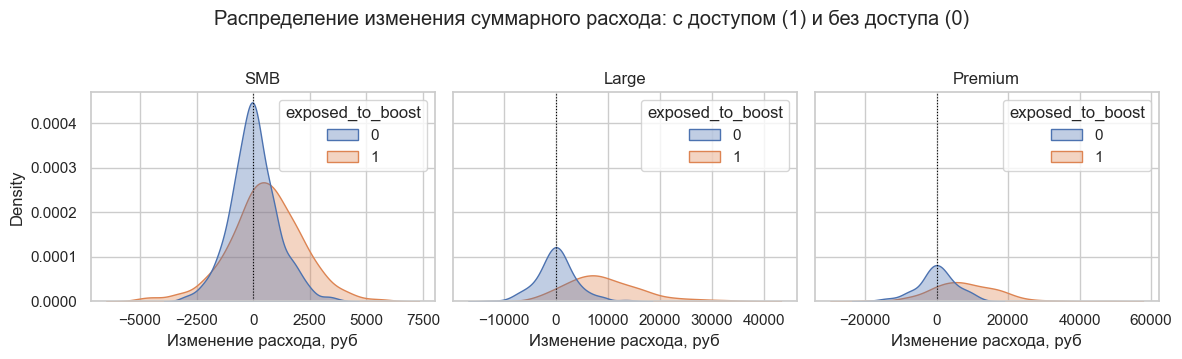

exposed_to_boost,0,1,uplift_exposed_minus_control
segment,,,
Large,82.3,9216.6,9134.3
Premium,43.8,7710.8,7667.0
SMB,25.5,546.3,520.8


In [21]:
# Смотрим распределение изменения расхода, а не только среднее
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5), sharey=True)
for ax, seg_name in zip(axes, ["SMB", "Large", "Premium"]):
    part = emp[emp["segment"] == seg_name]
    sns.kdeplot(
        data=part, x="delta_total", hue="exposed_to_boost",
        common_norm=False, ax=ax, fill=True, alpha=0.35,
    )
    ax.set_title(seg_name)
    ax.set_xlabel("Изменение расхода, руб")
    ax.axvline(0, color="black", lw=0.8, ls=":")
plt.suptitle("Распределение изменения суммарного расхода: с доступом (1) и без доступа (0)", y=1.02)
plt.tight_layout()
plt.show()

# Точечная оценка прироста: с доступом минус контроль
uplift = (
    summary.pivot(index="segment", columns="exposed_to_boost", values="mean_delta_total")
)
uplift["uplift_exposed_minus_control"] = uplift[1] - uplift[0]
uplift.round(1)


In [22]:
# Бутстрэп: устойчивость оценки прироста, не доказательство причинности
def bootstrap_uplift(df, segment, n_boot=800, seed=0):
    rng = np.random.default_rng(seed)
    part = df[df["segment"] == segment]
    exp = part.loc[part["exposed_to_boost"] == 1, "delta_total"].values
    ctrl = part.loc[part["exposed_to_boost"] == 0, "delta_total"].values
    stats = []
    for _ in range(n_boot):
        stats.append(rng.choice(exp, len(exp), replace=True).mean() - rng.choice(ctrl, len(ctrl), replace=True).mean())
    return np.mean(stats), np.percentile(stats, 2.5), np.percentile(stats, 97.5)

boot_rows = []
for seg_name in ["SMB", "Large", "Premium"]:
    mean, lo, hi = bootstrap_uplift(emp, seg_name)
    boot_rows.append({"segment": seg_name, "uplift_mean": mean, "ci_low": lo, "ci_high": hi})
boot = pd.DataFrame(boot_rows)
display(boot.round(1))

fig = go.Figure()
fig.add_trace(go.Scatter(
    x=boot["segment"], y=boot["uplift_mean"], mode="markers",
    error_y=dict(type="data", symmetric=False,
                 array=boot["ci_high"] - boot["uplift_mean"],
                 arrayminus=boot["uplift_mean"] - boot["ci_low"]),
    marker=dict(size=12, color="#4C78A8"),
))
fig.add_hline(y=0, line_dash="dot")
fig.update_layout(
    title="Прирост суммарного расхода (с доступом минус контроль), 95% доверительный интервал по бутстрэпу",
    height=380, yaxis_title="руб на работодателя", xaxis_title="Сегмент",
)
fig.show()


,segment,uplift_mean,ci_low,ci_high
0,SMB,517.2,364.2,660.8
1,Large,9150.6,8304.6,9969.1
2,Premium,7648.5,6137.6,9067.4


### Шаг 5. Правило принятия решения и вывод

| Сегмент | Ожидаемая картина в синтетике | Решение по критерию |
|---|---|---|
| Малый бизнес (SMB) | Сильное падение top_search, слабый инкремент суммарного расхода | Не раскатывать в текущем виде или менять прайс |
| Крупные (Large) | Умеренная каннибализация, заметный инкремент | Оставить |
| Премиум (Premium) | Смешанная картина | Оставить с мониторингом |

> Оговорка: это наблюдательная оценка без рандомизации. Смещение отбора (кто получил доступ к формату) полностью не устранено. Решение оставит след (бюджеты клиентов уже перетекут), поэтому вывод по малому бизнесу стоит подтвердить полноценным A/B-тестом.


In [23]:
# Применяем критерий из ТЗ автоматически
dec = cann_view.copy()
dec["keep_segment"] = (dec["delta_total_pct"] >= 0.10) & (dec["delta_ts_pct"] >= -0.15)
# У малого бизнеса критерий обычно не выполняется; проверим и альтернативное правило:
# инкремент должен превышать каннибализацию
dec["alt_keep"] = dec["incremental_est"] > dec["cannibalization_est"]
display(dec[["segment", "delta_ts_pct", "delta_total_pct", "keep_segment", "alt_keep"]])

print(
    one_pager(
        decision="Оставить новый формат для крупных клиентов и для премиума с мониторингом. Малому бизнесу не раскатывать в текущем виде: там преобладает каннибализация.",
        context="15 июля запустили формат top_boost. Вопрос: инкремент или каннибализация по чистому расходу и откликам.",
        what_done="Сравнили расход до и после, разложили расход нового формата на каннибализацию и инкремент, оценили прирост на уровне работодателя (с доступом против контроля) с доверительным интервалом по бутстрэпу.",
        result="У крупных клиентов прирост суммарного расхода уверенно выше нуля. У малого бизнеса суммарный расход почти не изменился при сильном падении top_search. У премиума умеренный инкремент.",
        limits="Нет рандомизации. Группа с доступом может отличаться по размеру бюджета. Каннибализация на шаге 3 — верхняя оценка через падение top_search.",
        action="1) Оставить малый бизнес в контроле. 2) Раскатать формат крупным. 3) Завести охранный дашборд: доля нового формата, изменение top_search, стоимость отклика. 4) Спланировать A/B по прайсу формата для малого бизнеса.",
    )
)


,segment,delta_ts_pct,delta_total_pct,keep_segment,alt_keep
0,Large,-0.10,0.19,True,True
1,Premium,-0.14,0.14,True,False
2,SMB,-0.31,0.02,False,False


ИТОГОВАЯ СПРАВКА

Решение:
Оставить новый формат для крупных клиентов и для премиума с мониторингом. Малому бизнесу не раскатывать в текущем виде: там преобладает каннибализация.

Контекст:
15 июля запустили формат top_boost. Вопрос: инкремент или каннибализация по чистому расходу и откликам.

Что сделали:
Сравнили расход до и после, разложили расход нового формата на каннибализацию и инкремент, оценили прирост на уровне работодателя (с доступом против контроля) с доверительным интервалом по бутстрэпу.

Результат:
У крупных клиентов прирост суммарного расхода уверенно выше нуля. У малого бизнеса суммарный расход почти не изменился при сильном падении top_search. У премиума умеренный инкремент.

Ограничения:
Нет рандомизации. Группа с доступом может отличаться по размеру бюджета. Каннибализация на шаге 3 — верхняя оценка через падение top_search.

Рекомендованное действие:
1) Оставить малый бизнес в контроле. 2) Раскатать формат крупным. 3) Завести охранный дашборд: доля нового формата,

### После кейса 4

Фраза «суммарный расход вырос» ещё не значит «формат полезен». У малого бизнеса рост верхней линии может быть перекладыванием бюджета. Решение посегментное. Шаг 3 подозревает каннибализацию, шаг 4 проверяет её относительно контроля.


## Кейс 5. Разбор эксперимента со скидками (опционально по времени)

### Контекст

Даже когда A/B уже закончился, ad-hoc часто нужен, чтобы принять решение о раскатке. Одной конверсии недостаточно: важны ценность клиента за наблюдаемое окно и удержание.

Группы по размеру скидки. В расчётах ниже смотрим порядок **контроль → 30% → 50%** (`A_0pct` → `C_30pct` → `B_50pct`), чтобы буква группы не путалась с величиной скидки.

| Группа | Скидка |
|---|---|
| A (`A_0pct`) | 0% (контроль) |
| C (`C_30pct`) | 30% |
| B (`B_50pct`) | 50% |

---

| Как говорим | Что это |
|---|---|
| Конверсия в первую кампанию | Доля новичков, запустивших первую кампанию |
| Ценность клиента за окно | Чистый расход за 30 и 56 дней (`ltv_net_30d` / `ltv_net_56d` в коде — это **не** пожизненная ценность) |
| Удержание за 30 дней | Доля вернувшихся в течение месяца |
| Оценка на всю группу | Среднее по всем, кого назначили в группу (аналог intent-to-treat): и конвертировавшихся, и нет |

---

| Поле ТЗ | Значение |
|---|---|
| Цель | Выбрать размер скидки с лучшей инкрементальной выручкой на горизонте ~2 месяцев |
| Гипотеза | Скидка 50% даёт больше клиентов, но снижает ценность; 30% даёт лучший баланс |
| Метрика | Конверсия на группу; ценность за 30/56 дней на конвертировавшегося и на всю группу; удержание 30 дней как охранная метрика |
| Период | Окно эксперимента и 56 дней наблюдения после входа (заложено в синтетике) |
| Сегменты | Группа скидки; при необходимости — сегмент клиента в данных |
| Критерий успеха | Максимум ценности за 56 дней на всю группу среди вариантов со скидкой; удержание 30 дней не хуже контроля заметно |
| Решение | Раскатать скидку 0%, 30% или 50% |
| Глубина | Глубокий разбор: цена ошибки средняя, но скидку получат реальные клиенты, этот след не отменить, поэтому ступень выше. Проверяем вывод на двух окнах (30 и 56 дней), по охранной метрике удержания и по распределению |


In [ ]:
clients = experiment_clients.copy()

# Оценка на всю группу (по назначению): конверсия и средняя ценность по всем попавшим
itt = (
    clients.groupby("group_name", as_index=False)
    .agg(
        n_entered=("client_id", "count"),
        n_converted=("converted", "sum"),
        mean_value30_all=("ltv_net_30d", "mean"),
        mean_value56_all=("ltv_net_56d", "mean"),
    )
)
itt["conversion"] = itt["n_converted"] / itt["n_entered"]

converted = clients[clients["converted"] == 1]
per_conv = (
    converted.groupby("group_name", as_index=False)
    .agg(
        n=("client_id", "count"),
        value30=("ltv_net_30d", "mean"),
        value56=("ltv_net_56d", "mean"),
        retention30=("returned_30d", "mean"),
    )
)

res = itt.merge(per_conv, on="group_name", suffixes=("_all", "_conv"))
base_a = res.loc[res["group_name"] == "A_0pct", "mean_value56_all"].iloc[0]
res["uplift_value56_vs_A"] = res["mean_value56_all"] - base_a
res["uplift_conv_vs_A"] = (
    res["conversion"] - res.loc[res["group_name"] == "A_0pct", "conversion"].iloc[0]
)

# Порядок: контроль → 30% → 50%
order = ["A_0pct", "C_30pct", "B_50pct"]
res = res.set_index("group_name").loc[order].reset_index()
res.round(4)


In [ ]:
fig = make_subplots(
    rows=1, cols=2,
    subplot_titles=(
        "Конверсия в первую кампанию (на всю группу)",
        "Ценность клиента за 30 дней на конвертировавшегося, ₽",
    ),
)

r = res
fig.add_trace(go.Bar(x=r["group_name"], y=r["conversion"], marker_color="#4C78A8"), 1, 1)
fig.add_trace(go.Bar(x=r["group_name"], y=r["value30"], marker_color="#F58518"), 1, 2)
fig.update_yaxes(tickformat=".0%", row=1, col=1)
fig.update_layout(
    height=400, showlegend=False,
    title_text="Большая скидка и высокая конверсия ещё не значат большую ценность",
)
fig.show()

fig2, ax = plt.subplots(figsize=(9, 4))
sns.violinplot(
    data=converted, x="group_name", y="ltv_net_30d",
    order=order, ax=ax, inner="quartile", color="#72B7B2",
)
ax.set_title("Распределение ценности клиента за 30 дней среди конвертировавшихся")
ax.set_ylabel("Ценность клиента за 30 дней, ₽")
ax.set_xlabel("Группа")
plt.tight_layout()
plt.show()


In [ ]:
# Правило ТЗ: лучшая ценность за 56 дней на всю группу среди скидок;
# удержание 30 дней не должно проседать заметно относительно контроля.
ctrl_ret = res.loc[res["group_name"] == "A_0pct", "retention30"].iloc[0]
cand = res[res["group_name"] != "A_0pct"].copy()
cand["retention_ok"] = cand["retention30"] >= ctrl_ret - 0.02
cand = cand.sort_values("mean_value56_all", ascending=False)
display(cand[["group_name", "conversion", "value30", "mean_value56_all", "retention30", "retention_ok"]])

best = cand.iloc[0]
print(
    f"Кандидат на раскат по правилу ТЗ: {best['group_name']} "
    f"(ценность за 56 дней на всю группу {best['mean_value56_all']:.0f} ₽; "
    f"удержание 30д={best['retention30']:.1%}, ок={bool(best['retention_ok'])})"
)

print(
    one_pager(
        decision="Раскатывать скидку 30% (группа C): лучший баланс конверсии и ценности за окно, выше ценность на всю группу, чем у 50%, удержание в допустимом коридоре.",
        context="Разбор эксперимента со скидками новичкам. Нужно решение о раскатке.",
        what_done="Посчитали конверсию на группу, ценность за 30 и 56 дней на конвертировавшихся и на всю группу, удержание; посмотрели распределение ценности.",
        result="Скидка 50%: максимум конверсии, минимальная ценность. Скидка 30%: лучшая ценность на попавшего в группу среди скидок при приемлемом удержании.",
        limits="Экстраполяцию на 12 месяцев не делаем без кривых выживаемости. Стоимость бонусов в прибыль здесь не заведена.",
        action="Раскатать скидку 30%. Вариант 50% не раскатывать без пересмотра лимита бонусов. Мониторить удержание за 30 дней.",
    )
)


### После кейса 5

Смотрели компромисс конверсии, ценности за окно и удержания. Оценка на всю группу важна: скидка меняет и число клиентов, и их состав. Не превращайте «ценность за 30 дней» в «ценность за год» умножением на 12.


### Заметка про экстраполяцию ценности клиента

Не умножайте «ценность за 30 дней» на 12 и не называйте это «ценностью за год»: без модели выживаемости это переоценивает результат. Для решения «30% против 50%» обычно достаточно метрики на наблюдаемом окне в расчёте на всю группу плюс явных ограничений.


# Сводные шпаргалки

Полный пакет также в `lecture_adhoc.md`.

## Перед любым ad-hoc

- [ ] Понятно, какое **решение** примут по ответу
- [ ] Записаны проблема, цель, гипотеза и решение
- [ ] Выбрана ступень глубины: прикидка, разбор или глубокий разбор (по цене ошибки; если откатить без следа нельзя, ступень выше), и заказчик её слышал
- [ ] Пройдены семь вопросов до SQL (раздел 2.2) или пропуски оговорены
- [ ] ТЗ записано в чат (шаблон в разделе 2.3)
- [ ] Вы и заказчик одинаково понимаете, что значит «готово»

## Быстрые правила

| Ситуация | Что делать |
|---|---|
| «Посчитай X» без «зачем» | Спросить, какое решение примут по ответу |
| Один вопрос даёт три разных анализа | Уточнить решение до SQL |
| Тот же ad-hoc пришёл третий раз от разных заказчиков | Кандидат на отчёт или дашборд |
| После сдачи просят «ещё разрезы» | Новый разрез — это новая задача |
| Высокая цена ошибки, а времени мало | Сразу сказать заказчику, что успеете только прикидку и чего она не покрывает |
| Просят только кликабельность | Проверить всю воронку до целевого действия |
| Растёт новый продукт | Разложить эффект на инкремент и каннибализацию |

## Чек-лист визуализации ad-hoc

- [ ] График читается за несколько секунд без пояснений
- [ ] Есть сравнение: период, сегмент или тест и контроль
- [ ] Показано не только среднее, но и распределение или доверительный интервал
- [ ] На графике отмечены решение или порог
- [ ] В итоговой справке один главный график, а не пять


# Домашнее задание

**Формат сдачи:** ноутбук, итоговая справка на одну страницу и **2** ключевых графика.

Возьмите синтетику из папки `data/` (показы / клики / отклики).

### В работе должно быть

- [ ] ТЗ по семи вопросам до SQL: решение сформулировано до анализа
- [ ] Выбранная ступень глубины (прикидка, разбор или глубокий разбор) и пара предложений, почему: цена ошибки и можно ли откатить без следа
- [ ] Раздел про качество данных: что проверили и что нашли
- [ ] Минимум 2 информативных графика (распределения, интервалы и пр.)
- [ ] Вывод в виде действия, а не наблюдения
- [ ] Ограничения: что не проверили и что могло исказить результат

### Базовая тема (одно решение)

> 20 июля на Android кликабельность `top_search` резко выше обычной. Что это: ошибка трекинга, и тогда чиним логирование, или реальный эффект, и тогда решаем, менять ли формат показа на Android?

Соберите ТЗ, проверьте качество данных, покажите воронку/кликабельность с интервалом и распределением, сформулируйте решение.

### Бонус (необязательно)

Связать вывод с динамикой расхода `top_search` / `top_boost` после 15 июля — только если базовая часть уже закрыта.


# Книги и материалы

| Источник | Чем полезен |
|---|---|
| Cathy Tanimura, *SQL for Data Analysis* | SQL для воронок, когорт и экспериментов |
| Kohavi, Tang, Xu, *Trustworthy Online Controlled Experiments* | Дизайн и интерпретация A/B-тестов |
| Павел Безручко, *Без воды: как писать предложения и отчёты для первых лиц* | Как писать чёткие выводы |
| Cole Nussbaumer Knaflic, *Storytelling with Data* | Как упаковать вывод для заказчиков |
| Matheus Facure, *Causal Inference in Python* | Когда A/B нет: разность разностей, смещения |
| Wes McKinney, *Python for Data Analysis* | pandas и воспроизводимый анализ |